In [15]:
import os
import re
import tarfile
import urllib.request
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [16]:
#建立data資料夾
os.makedirs("data", exist_ok=True)
#下載IMDb
url="http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
filepath="data/aclImdb_v1.tar.gz"
if not os.path.isfile(filepath):
    result=urllib.request.urlretrieve(url,filepath)
    print('downloaded:',result)

In [17]:
#解壓縮IMDb
if not os.path.exists("data/aclImdb"):
    with tarfile.open(filepath, 'r:gz') as tfile:
        tfile.extractall('data/')

In [18]:
#定義rm_tags(text)函數
def rm_tags(text):
    re_tag = re.compile(r'<[^>]+>')
    return re_tag.sub('', text)

In [19]:
#定義 read_files(filetype)函數
def read_files(filetype):
    path = "data/aclImdb/"
    file_list=[]

    positive_path=path + filetype+"/pos/"
    for f in os.listdir(positive_path):
        file_list+=[positive_path+f]

    negative_path=path + filetype+"/neg/"
    for f in os.listdir(negative_path):
        file_list+=[negative_path+f]

    print('read',filetype, 'files:',len(file_list))

    all_labels = ([1] * 12500 + [0] * 12500)

    all_texts  = []
    for fi in file_list:
        with open(fi,encoding='utf8') as file_input:
            all_texts += [rm_tags(" ".join(file_input.readlines()))]

    return all_labels,all_texts

In [20]:
#建立訓練與測試資料
y_train, train_text = read_files("train")

read train files: 25000


In [21]:
y_test, test_text = read_files("test")

read test files: 25000


In [22]:
#建立字典與文字轉固定長度數字序列

NUM_WORDS = 2000#字典字數
MAX_LEN = 100#向量串長度

tokenizer = Tokenizer(num_words=NUM_WORDS)
tokenizer.fit_on_texts(train_text)
print('字典文件總數:', tokenizer.document_count)
print('字典前10項:', list(tokenizer.word_index.items())[:10])

# 轉換為數字串
x_train_seq = tokenizer.texts_to_sequences(train_text)
x_test_seq  = tokenizer.texts_to_sequences(test_text)

# 補零或截減使每篇長度皆為100
x_train = pad_sequences(x_train_seq, maxlen=MAX_LEN)
x_test  = pad_sequences(x_test_seq,  maxlen=MAX_LEN)

y_train = np.array(y_train)
y_test  = np.array(y_test)

np.random.seed(42)
indices = np.arange(len(x_train))
np.random.shuffle(indices)
x_train = x_train[indices]
y_train = y_train[indices]

字典文件總數: 25000
字典前10項: [('the', 1), ('and', 2), ('a', 3), ('of', 4), ('to', 5), ('is', 6), ('in', 7), ('it', 8), ('i', 9), ('this', 10)]


In [23]:
#建立神經網路模型
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

EMBEDDING_DIM = 32
LSTM_UNITS = 16

model = Sequential([

    Embedding(input_dim=NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    #Embedding層：
    #Input shape: (None, 100)
    #Output shape: (None, 100, 32)
    #參數計算    : 2000 * 32 = 64,000

    LSTM(units=LSTM_UNITS),
    #LSTM 層：
   #Input shape: (None, 100, 32)
  #Output shape: (None, 16)
   #參數計算:4*[48 * 16 +16] = 4 * 784 = 3,136

    Dropout(0.5),

    Dense(units=1, activation='sigmoid')
     #Dense 層：
    #Input shape: (None, 16)
    #Output shape: (None, 1)
   #參數計算: 16*1 + 1 = 17
])

model.build(input_shape=(None, MAX_LEN))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 32)        │        64,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,153 (262.32 KB)

 Trainable params: 67,153 (262.32 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
#訓練模型

model.compile(loss='binary_crossentropy',optimizer='adam',
              metrics=['accuracy'])
train_history = model.fit(x_train, y_train,
              batch_size=128,
              epochs=10,
              verbose=2,
              validation_split=0.2)

Epoch 1/10
157/157 - 15s - 97ms/step - accuracy: 0.7197 - loss: 0.5643 - val_accuracy: 0.8206 - val_loss: 0.4154
Epoch 2/10
157/157 - 11s - 68ms/step - accuracy: 0.8530 - loss: 0.3743 - val_accuracy: 0.8404 - val_loss: 0.3687
Epoch 3/10
157/157 - 22s - 137ms/step - accuracy: 0.8727 - loss: 0.3296 - val_accuracy: 0.8372 - val_loss: 0.3606
Epoch 4/10
157/157 - 13s - 83ms/step - accuracy: 0.8796 - loss: 0.3101 - val_accuracy: 0.8410 - val_loss: 0.3548
Epoch 5/10
157/157 - 21s - 131ms/step - accuracy: 0.8880 - loss: 0.2911 - val_accuracy: 0.8458 - val_loss: 0.3550
Epoch 6/10
157/157 - 12s - 76ms/step - accuracy: 0.8956 - loss: 0.2769 - val_accuracy: 0.8402 - val_loss: 0.3674
Epoch 7/10
157/157 - 22s - 138ms/step - accuracy: 0.8971 - loss: 0.2715 - val_accuracy: 0.8436 - val_loss: 0.3564
Epoch 8/10
157/157 - 17s - 105ms/step - accuracy: 0.9050 - loss: 0.2566 - val_accuracy: 0.8394 - val_loss: 0.3594
Epoch 9/10
157/157 - 13s - 80ms/step - accuracy: 0.9067 - loss: 0.2503 - val_accuracy: 0.831

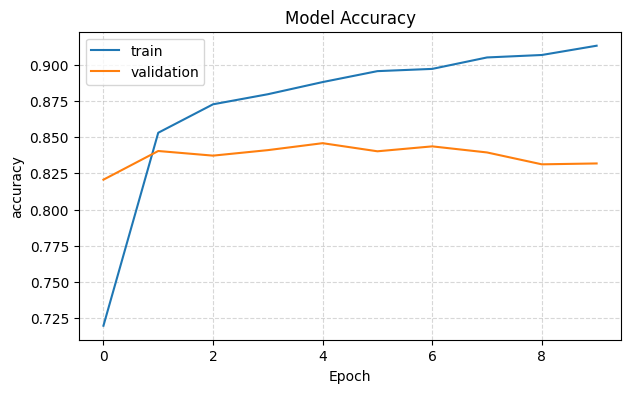

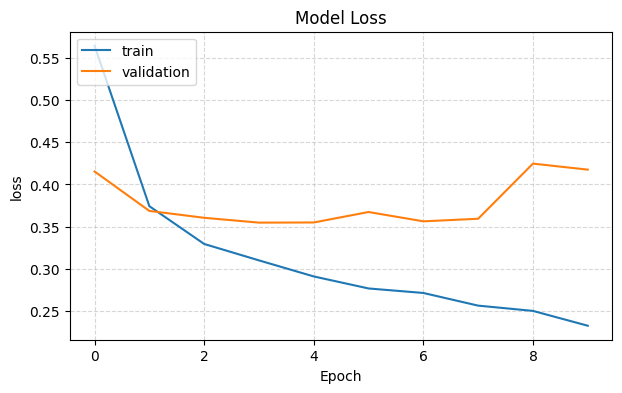

In [25]:
#Loss和Accuracy折線圖
import matplotlib.pyplot as plt

def show_train_history(history, train_metric, val_metric, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history.history[train_metric], label='train')
    plt.plot(history.history[val_metric], label='validation')
    plt.title(title)
    plt.ylabel(train_metric)
    plt.xlabel('Epoch')
    plt.legend(loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

show_train_history(train_history, 'accuracy', 'val_accuracy', 'Model Accuracy')
show_train_history(train_history, 'loss', 'val_loss', 'Model Loss')


In [26]:
#評估模型準確率
scores = model.evaluate(x_test, y_test, verbose=1)
print(f"Test Loss: {scores[0]:.4f}")
print(f"Test Accuracy: {scores[1]:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8397 - loss: 0.4195
Test Loss: 0.4195
Test Accuracy: 0.8397


In [27]:
from google.colab import drive

drive.mount('/content/drive')
%cd "/content/drive/MyDrive/python github/"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/python github


In [31]:
import pickle
model_json = model.to_json()
open('imdb_model_architecture.json', 'w').write(model_json)
model.save_weights('imdb_modell_weights.weights.h5')